In [1]:
import pickle
import json
path = "./interval.pkl"

json_path = "/source/ms/highlight/json/8LwZsvWFmrY.json"
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

In [2]:
random_intervals = [
    (16, 27),
   (269, 280),
   (438, 449),
   (547, 558),
   (587, 598) 
]

In [3]:
with open(path, 'rb') as f:
    print("import pickle!!!")
    dp_intervals, threshold_c, threshold_intervals, knapsack_intervals = pickle.load(f)

import pickle!!!


In [4]:
from scipy.interpolate import interp1d
import numpy as np
def interpolate(start_seconds, intensity_scores):
    interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")
    total_duration_seconds = start_seconds[-1]
    new_time = np.arange(0, total_duration_seconds, 1)
    smoothed_intensity_scores = interpolation_function(new_time)

    # half_cut = int(len(smoothed_intensity_scores)/2)
    # smoothed_intensity_scores = smoothed_intensity_scores[:half_cut]
    smoothed_intensity_scores = interpolation_function(new_time)
    return new_time, smoothed_intensity_scores

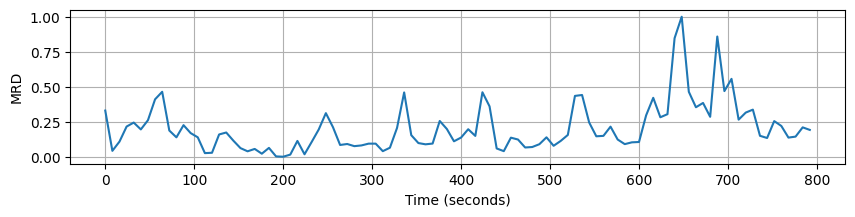

In [5]:
import matplotlib.pyplot as plt


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(10, 2))
plt.plot(start_seconds, intensity_scores)
# plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('MRD')
plt.grid(True)
plt.show()

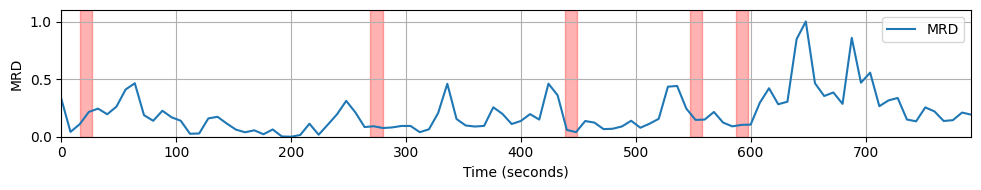

In [7]:
# 그래프 그리기
plt.figure(figsize=(10, 2))
plt.plot(start_seconds, intensity_scores, label='MRD')

# random_intervals 표시
for interval in random_intervals:
    start, end = interval
    plt.axvspan(start, end, color='red', alpha=0.3)

plt.xlabel('Time (seconds)')
plt.ylabel('MRD')
plt.grid(True)
plt.legend()

# y축 범위 설정 (0부터 최대값까지)
plt.ylim(0, max(intensity_scores) * 1.1)

# x축 범위 설정 (0부터 비디오 끝까지)
plt.xlim(0, max(start_seconds))

plt.tight_layout()
plt.show()